# Week 2 Task: Exploratory Data Analysis and Visualization

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_dataset.csv")

df.dtypes

Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             object
Rating text              object
Votes                     int64
dtype: object

In [2]:
sns.set_style("whitegrid")


In [3]:
print("Shape:" , df.shape)
print("\nHead:", df.head(3))

Shape: (9551, 21)

Head:    Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   

                                    Locality Verbose   Longitude   Latitude  \
0  Century City Mall, Poblacion, Makati City, Mak...  121.027535  14.565443   
1  Little Tokyo, Legaspi Village, Makati City, Ma...  121.014101  14.553708   
2  Edsa Sha

In [4]:
print("Describe:", df.describe())

print("\nDescribe (object):", df.describe(include="object"))

Describe:        Restaurant ID  Country Code    Longitude     Latitude  \
count   9.551000e+03   9551.000000  9551.000000  9551.000000   
mean    9.051128e+06     18.365616    64.126574    25.854381   
std     8.791521e+06     56.750546    41.467058    11.007935   
min     5.300000e+01      1.000000  -157.948486   -41.330428   
25%     3.019625e+05      1.000000    77.081343    28.478713   
50%     6.004089e+06      1.000000    77.191964    28.570469   
75%     1.835229e+07      1.000000    77.282006    28.642758   
max     1.850065e+07    216.000000   174.832089    55.976980   

       Average Cost for two  Price range  Aggregate rating         Votes  
count           9551.000000  9551.000000       9551.000000   9551.000000  
mean            1199.210763     1.804837          2.666370    156.909748  
std            16121.183073     0.905609          1.516378    430.169145  
min                0.000000     1.000000          0.000000      0.000000  
25%              250.000000     1.0000

In [5]:
numeric_cols = ['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes'
]

print("Describe (numeric):", df[numeric_cols].describe())

Describe (numeric):        Average Cost for two  Price range  Aggregate rating         Votes
count           9551.000000  9551.000000       9551.000000   9551.000000
mean            1199.210763     1.804837          2.666370    156.909748
std            16121.183073     0.905609          1.516378    430.169145
min                0.000000     1.000000          0.000000      0.000000
25%              250.000000     1.000000          2.500000      5.000000
50%              400.000000     2.000000          3.200000     31.000000
75%              700.000000     2.000000          3.700000    131.000000
max           800000.000000     4.000000          4.900000  10934.000000


In [6]:
df[numeric_cols].mean()

Average Cost for two    1199.210763
Price range                1.804837
Aggregate rating           2.666370
Votes                    156.909748
dtype: float64

In [7]:
df[numeric_cols].median()

Average Cost for two    400.0
Price range               2.0
Aggregate rating          3.2
Votes                    31.0
dtype: float64

In [8]:
df[numeric_cols].mode().iloc[0]

Average Cost for two    500.0
Price range               1.0
Aggregate rating          0.0
Votes                     0.0
Name: 0, dtype: float64

In [9]:
df[numeric_cols].max() - df[numeric_cols].min()

Average Cost for two    800000.0
Price range                  3.0
Aggregate rating             4.9
Votes                    10934.0
dtype: float64

In [10]:
df['Aggregate rating'].describe()

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

In [11]:
df['Aggregate rating'].value_counts().sort_index()

Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64

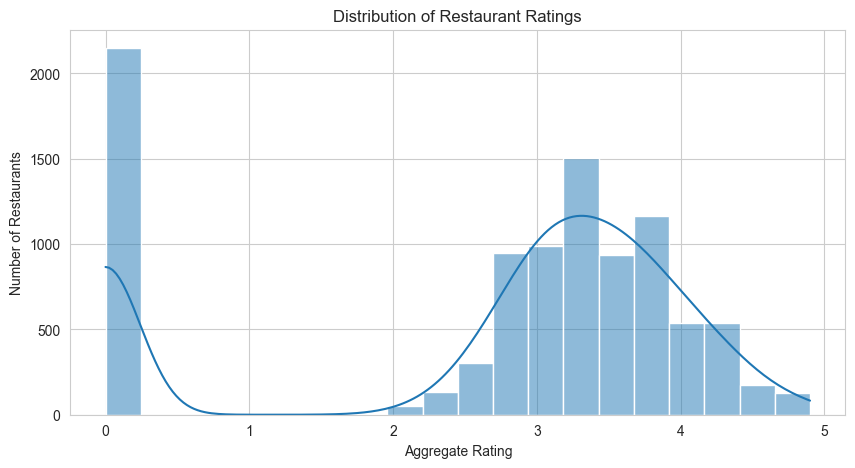

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Aggregate rating'],
    bins=20,
    kde=True
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Aggregate Rating')
plt.ylabel('Number of Restaurants')

plt.show()

In [13]:
df['Price range'].value_counts().sort_index()

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

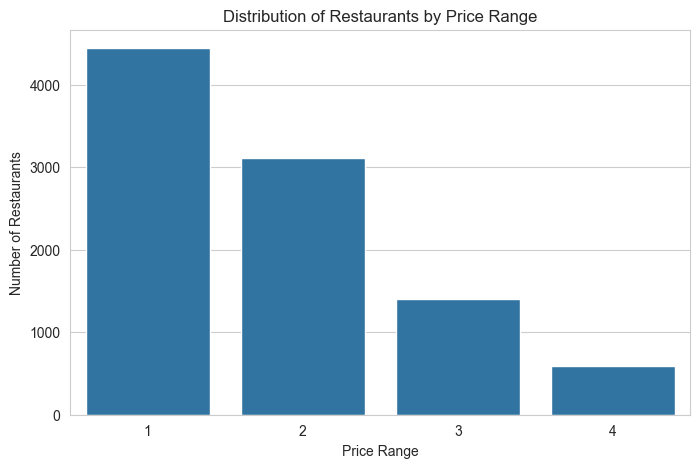

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Price range'
)

plt.title('Distribution of Restaurants by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Number of Restaurants')

plt.show()

In [15]:
df['Votes'].describe()

count     9551.000000
mean       156.909748
std        430.169145
min          0.000000
25%          5.000000
50%         31.000000
75%        131.000000
max      10934.000000
Name: Votes, dtype: float64

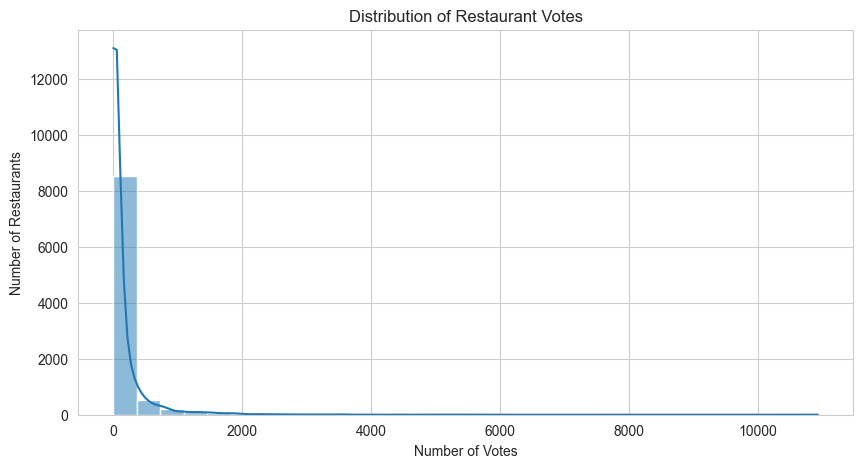

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Votes'],
    bins=30,
    kde=True
)

plt.title('Distribution of Restaurant Votes')
plt.xlabel('Number of Votes')
plt.ylabel('Number of Restaurants')
plt.show()

In [17]:
df['Average Cost for two'].describe()

count      9551.000000
mean       1199.210763
std       16121.183073
min           0.000000
25%         250.000000
50%         400.000000
75%         700.000000
max      800000.000000
Name: Average Cost for two, dtype: float64

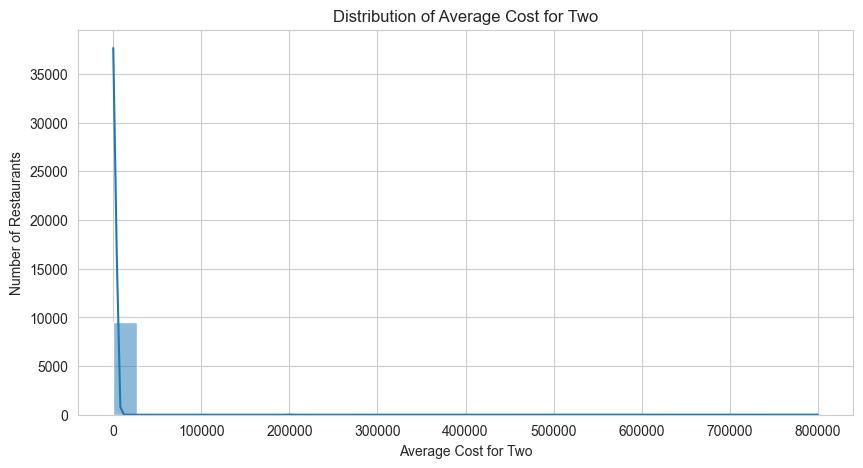

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Average Cost for two'],
    bins=30,
    kde=True
)

plt.title('Distribution of Average Cost for Two')
plt.xlabel('Average Cost for Two')
plt.ylabel('Number of Restaurants')
plt.show()

In [24]:
numeric_cols = [
    "Average Cost for two",
    "Price range",
    "Aggregate rating",
    "Votes"
]

correlation = df[numeric_cols].corr()

print(correlation)


                      Average Cost for two  Price range  Aggregate rating  \
Average Cost for two              1.000000     0.075083          0.051792   
Price range                       0.075083     1.000000          0.437944   
Aggregate rating                  0.051792     0.437944          1.000000   
Votes                             0.067783     0.309444          0.313691   

                         Votes  
Average Cost for two  0.067783  
Price range           0.309444  
Aggregate rating      0.313691  
Votes                 1.000000  


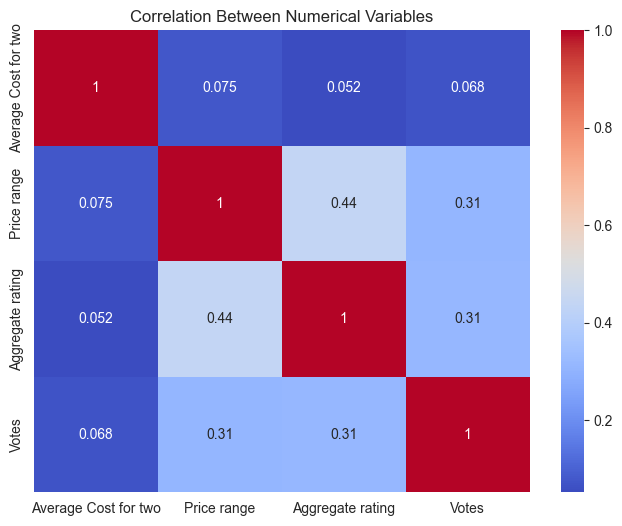

In [25]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Numerical Variables")

plt.show()


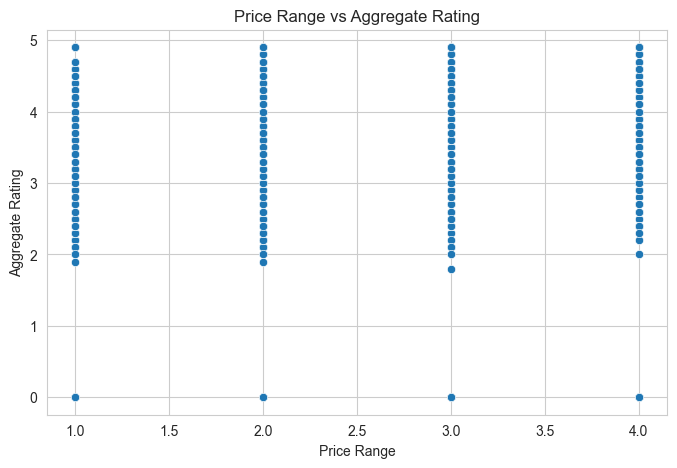

In [22]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Price range",
    y="Aggregate rating"
)

plt.title("Price Range vs Aggregate Rating")
plt.xlabel("Price Range")
plt.ylabel("Aggregate Rating")

plt.show()


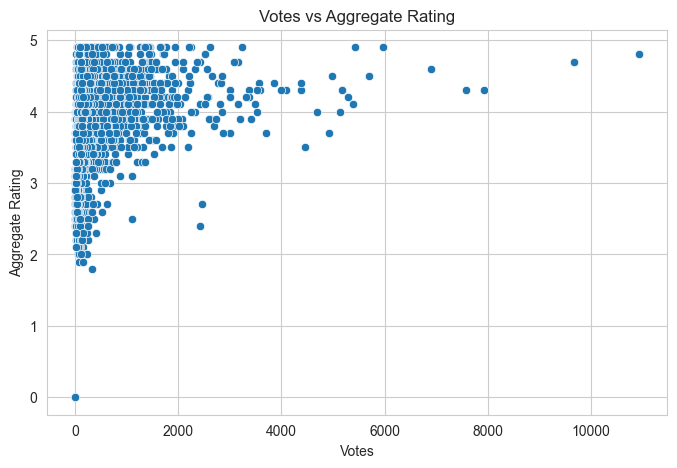

In [20]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Votes",
    y="Aggregate rating"
)

plt.title("Votes vs Aggregate Rating")
plt.xlabel("Votes")
plt.ylabel("Aggregate Rating")

plt.show()
